# 07. HH Demographic và Label

Notebook giữ hai góc nhìn bổ sung cho nhau:

1. Phân phối category trong Positive và Negative: $P(category \mid label)$.
2. Positive rate của từng category: $P(label=1 \mid category)$.

Toàn bộ logic phân tích và plotting nằm trong các module Python; notebook chỉ điều phối và hiển thị.

In [34]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.demographic_label import (
    build_demographic_label_report,
    load_demographic_label_panel,
)
from propensity.eda.demographic_label_plots import (
    plot_label_distributions,
    plot_positive_rate_by_category,
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Build report

In [35]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
demographic_path = project_root / "data" / "raw" / "Dunnhumby" / "hh_demographic.csv"

panel = load_demographic_label_panel(label_path, demographic_path)
report = build_demographic_label_report(panel)


## 2. Quy mô hai label

In [36]:
report.label_overview

,label,label_name,n_rows,n_households,n_cutoffs,row_share
0,0,Negative,94821,2457,81,0.4688
1,1,Positive,107423,2491,81,0.5312


## 3. Phân phối category trong Positive và Negative

Mỗi màu cộng thành 100% riêng trong label tương ứng. Biểu đồ này trả lời demographic composition của hai lớp khác nhau như thế nào.

In [37]:
report.distribution_summary

,feature,label,label_name,category,n_rows,n_households,within_label_share
0,AGE_DESC,0,Negative,19-24,869,45,0.0092
1,AGE_DESC,0,Negative,25-34,2866,140,0.0302
2,AGE_DESC,0,Negative,35-44,3593,183,0.0379
3,AGE_DESC,0,Negative,45-54,5346,278,0.0564
4,AGE_DESC,0,Negative,55-64,951,58,0.0100
...,...,...,...,...,...,...,...
91,KID_CATEGORY_DESC,1,Positive,1,7045,114,0.0656
92,KID_CATEGORY_DESC,1,Positive,2,3803,60,0.0354
93,KID_CATEGORY_DESC,1,Positive,3+,4127,69,0.0384
94,KID_CATEGORY_DESC,1,Positive,NO_DEMOGRAPHIC_RECORD,57740,1690,0.5375


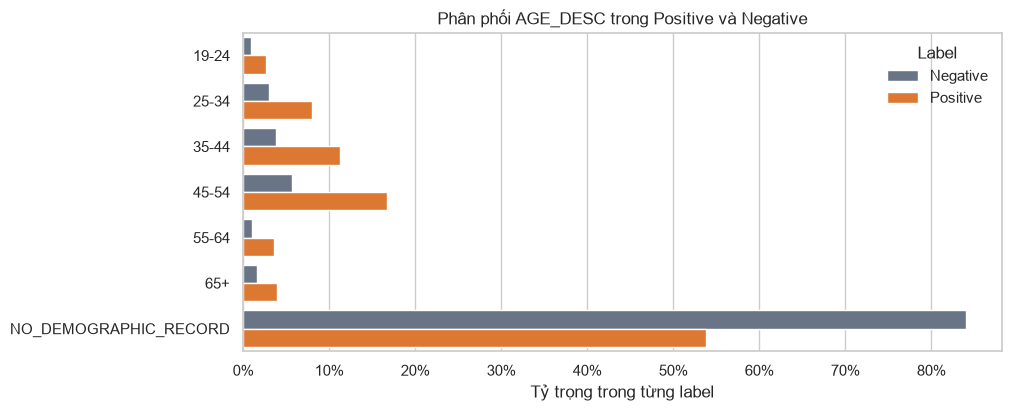

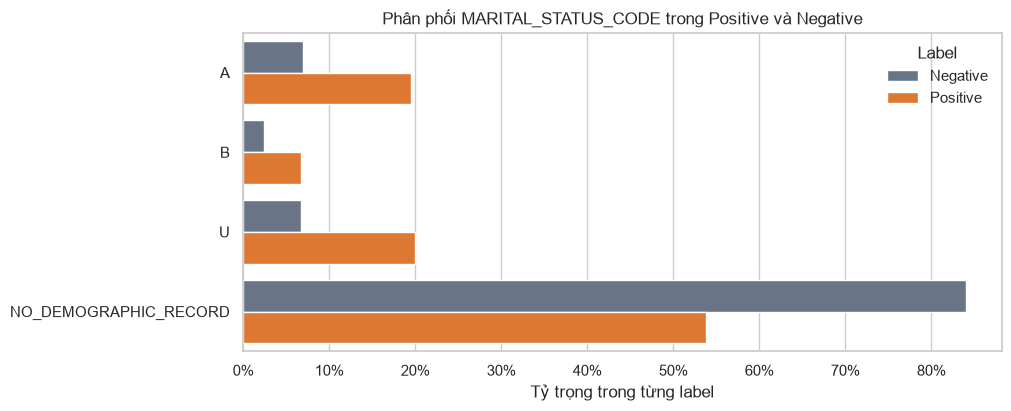

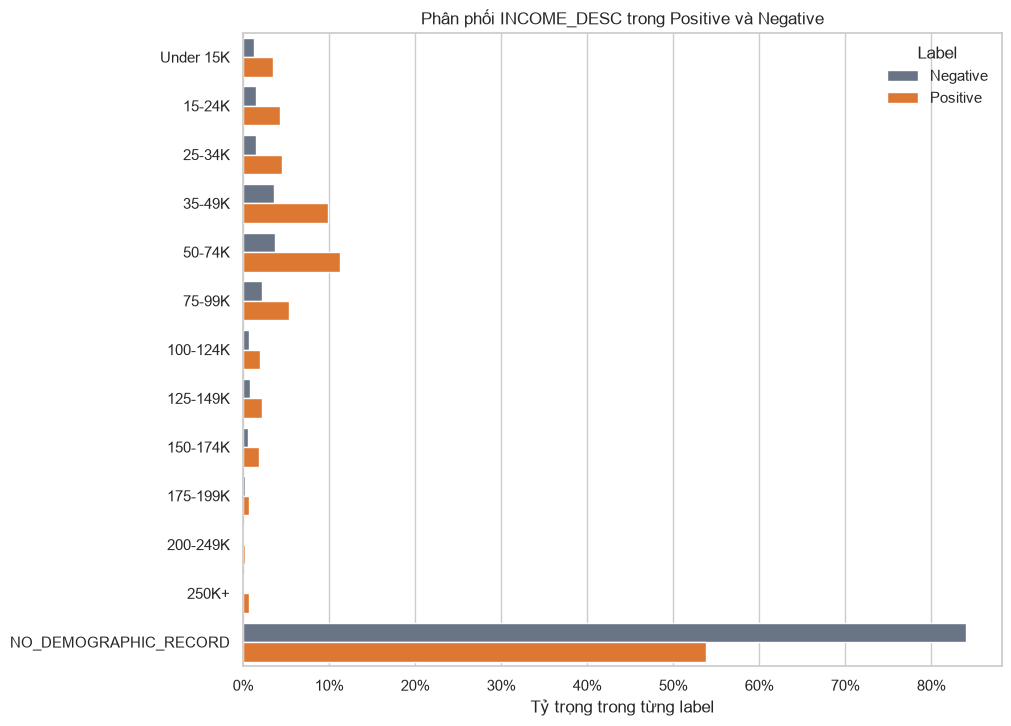

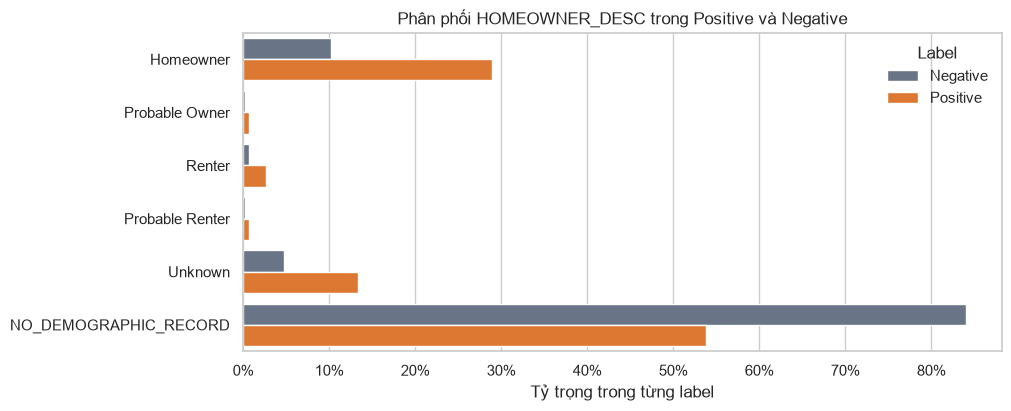

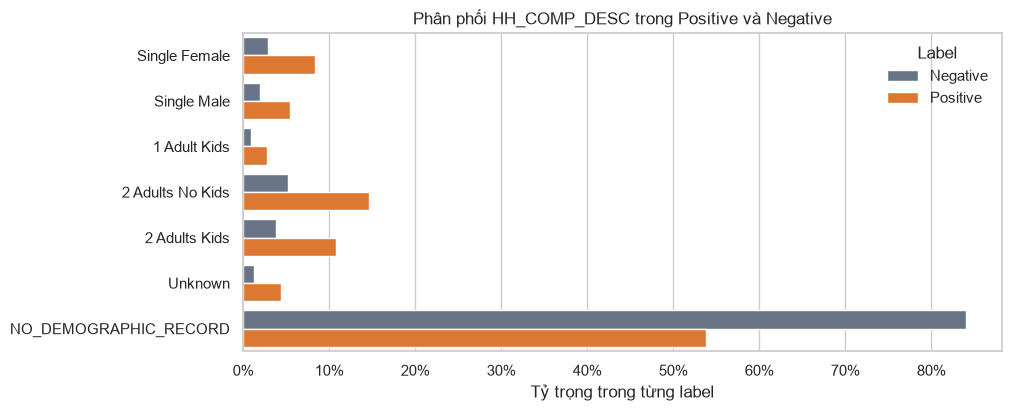

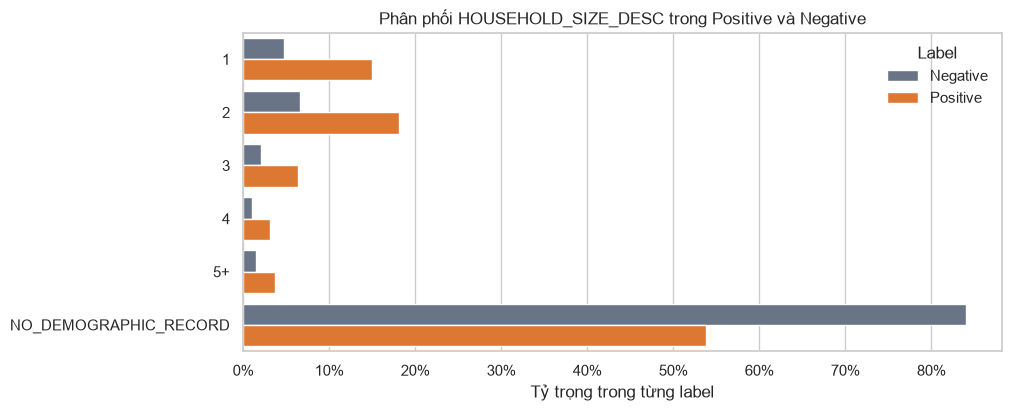

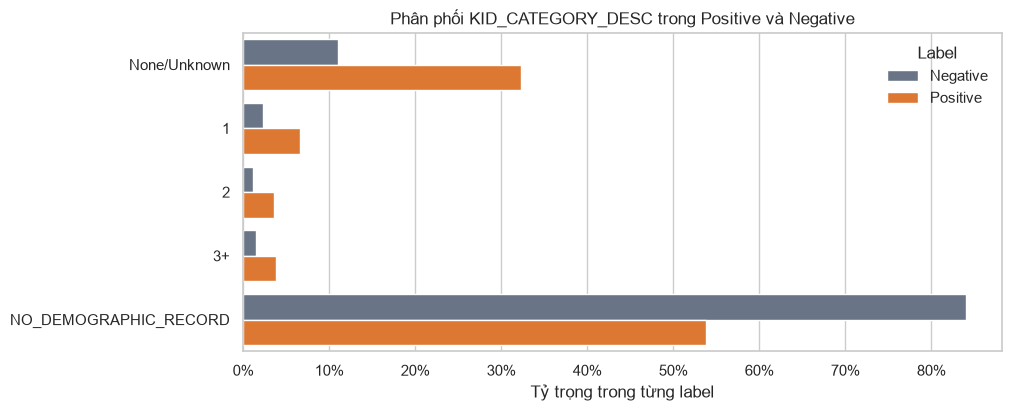

In [38]:
distribution_figures = plot_label_distributions(report.distribution_summary)
plt.show()

## 4. Positive Rate theo từng category

Phần này thay thế box plot. Mỗi category chỉ có một cột ngang biểu diễn:

$$\text{Positive Rate}=\frac{\#(label=1)}{\#(label=0)+\#(label=1)}$$

Đường đỏ nét đứt là positive rate chung của toàn panel. `NO_DEMOGRAPHIC_RECORD` không xuất hiện trong biểu đồ chính vì đây là trạng thái thiếu dữ liệu.

In [39]:
report.positive_rate_summary.sort_values(
    ["feature", "positive_rate"],
    ascending=[True, False],
)

,feature,category,n_observations,n_positive,n_households,n_negative,positive_rate,is_missing_category
4,AGE_DESC,55-64,4779,3828,59,951,0.8010,False
2,AGE_DESC,35-44,15714,12121,194,3593,0.7714,False
3,AGE_DESC,45-54,23328,17982,288,5346,0.7708,False
0,AGE_DESC,19-24,3726,2857,46,869,0.7668,False
1,AGE_DESC,25-34,11502,8636,142,2866,0.7508,False
5,AGE_DESC,65+,5832,4259,72,1573,0.7303,False
6,AGE_DESC,NO_DEMOGRAPHIC_RECORD,137363,57740,1699,79623,0.4203,True
36,HH_COMP_DESC,Unknown,5913,4667,73,1246,0.7893,False
34,HH_COMP_DESC,Single Female,11664,8978,144,2686,0.7697,False
30,HH_COMP_DESC,1 Adult Kids,3807,2928,47,879,0.7691,False


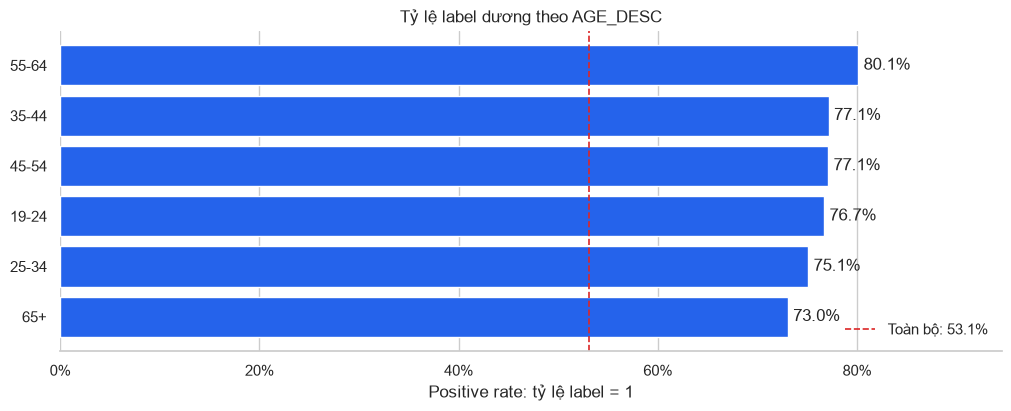

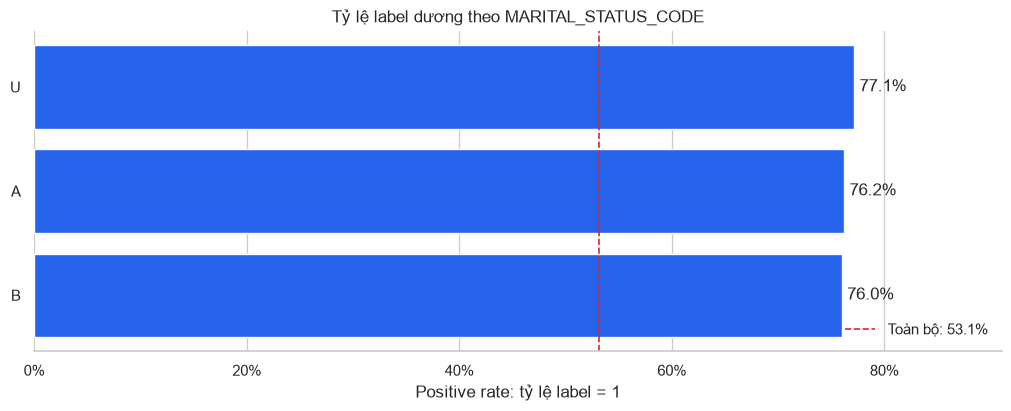

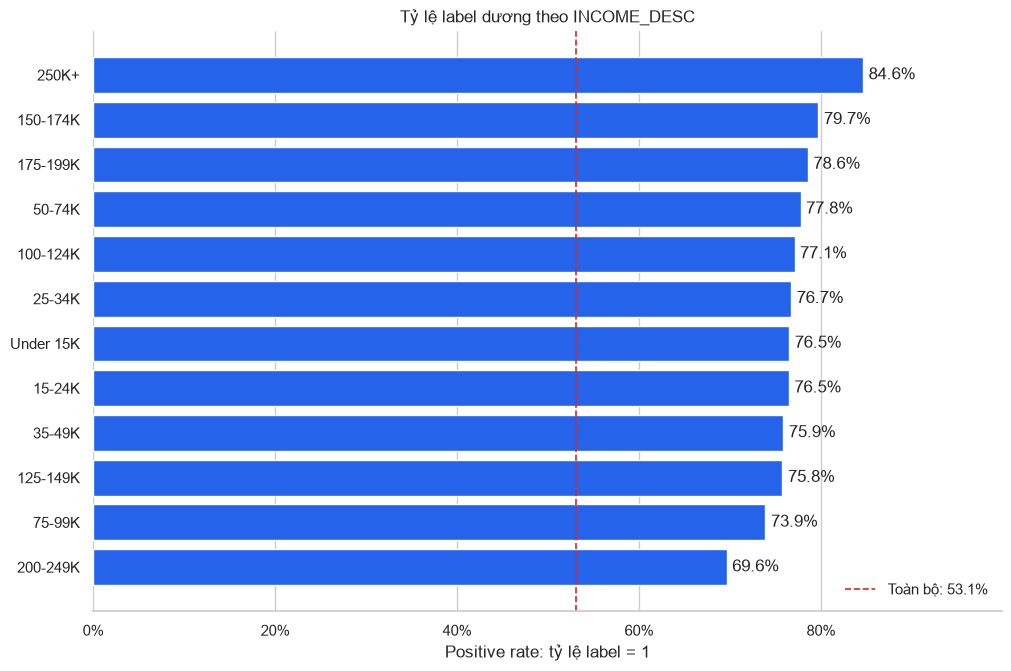

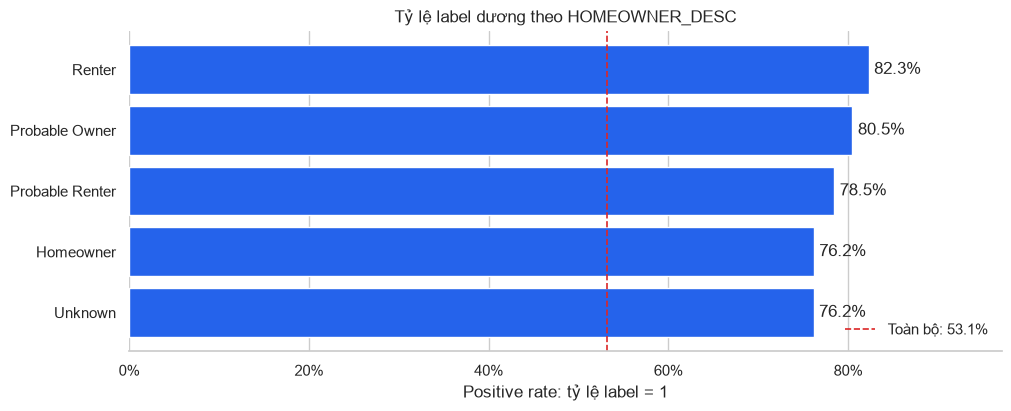

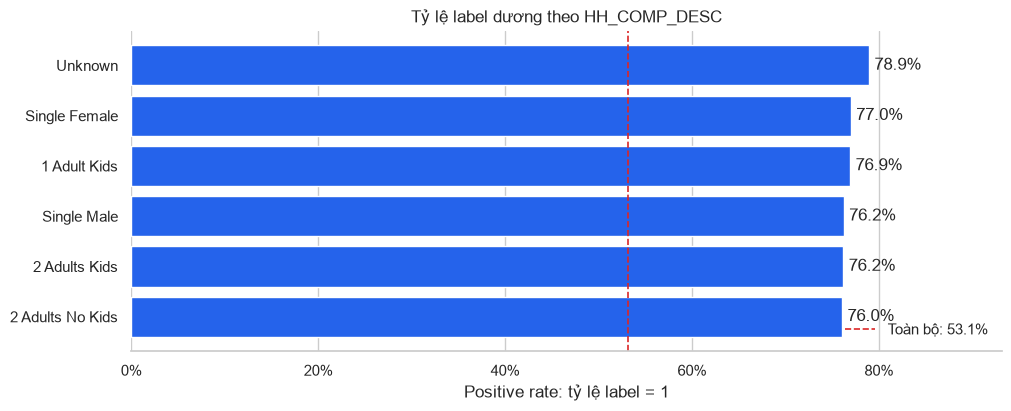

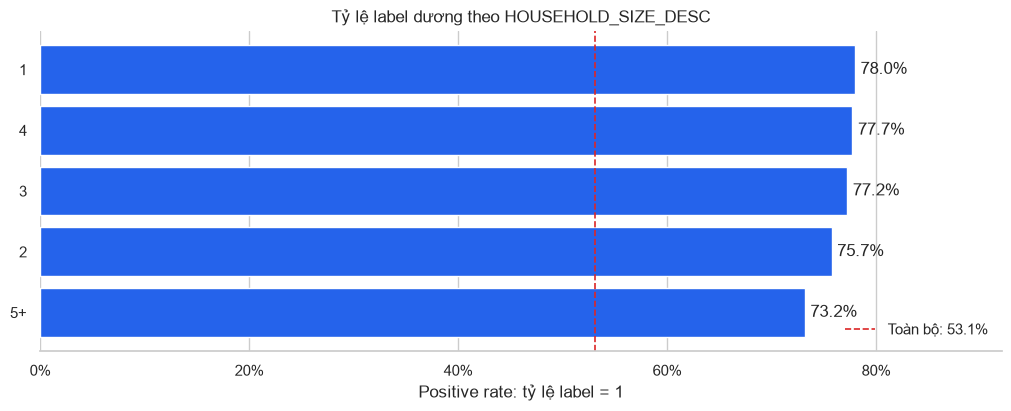

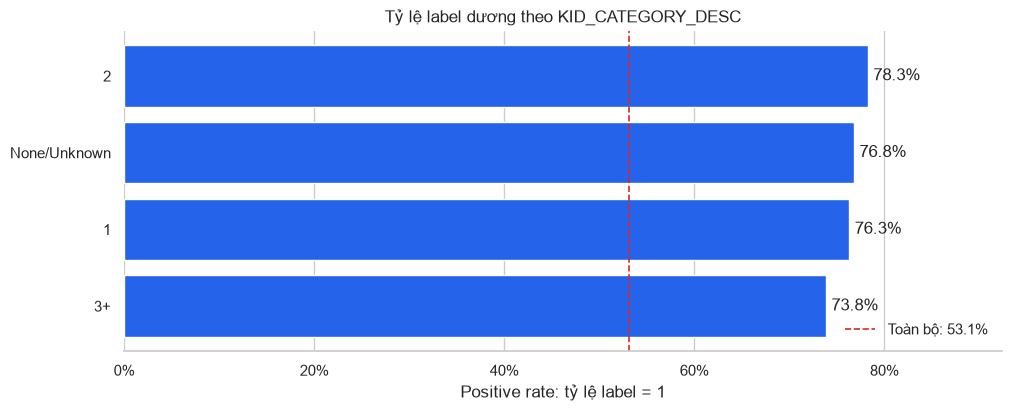

In [40]:
positive_rate_figures = plot_positive_rate_by_category(
    report.positive_rate_summary,
    report.overall_positive_rate,
)
plt.show()

## 5. Household overlap giữa hai label

Demographic là thuộc tính tĩnh nhưng label thay đổi theo cutoff. Bảng này cho biết bao nhiêu household từng xuất hiện ở cả hai label.

In [41]:
report.household_label_overlap

,n_households,n_households_in_both_labels,share_households_in_both_labels
0,2500,2448,0.9792


## 6. Chênh lệch category và khoảng cách phân phối

`positive_minus_negative_pp` dương nghĩa category phổ biến hơn trong Positive; âm nghĩa phổ biến hơn trong Negative. Total-variation distance loại `NO_DEMOGRAPHIC_RECORD` và chuẩn hóa lại trong các dòng có demographic.

In [42]:
report.feature_distance_summary

,feature,total_absolute_gap_pp,total_variation_distance
0,HOUSEHOLD_SIZE_DESC,6.8237,0.0341
1,AGE_DESC,6.5065,0.0325
2,INCOME_DESC,6.3876,0.0319
3,HOMEOWNER_DESC,4.2159,0.0211
4,HH_COMP_DESC,3.4040,0.0170
5,KID_CATEGORY_DESC,3.0727,0.0154
6,MARITAL_STATUS_CODE,2.7493,0.0137


In [43]:
report.category_gap_summary

,feature,category,Negative,Positive,positive_minus_negative_pp,absolute_gap_pp
0,AGE_DESC,65+,0.1035,0.0857,-1.7777,1.7777
1,AGE_DESC,25-34,0.1886,0.1738,-1.4755,1.4755
2,AGE_DESC,55-64,0.0626,0.0770,1.4474,1.4474
3,AGE_DESC,45-54,0.3518,0.3619,1.0178,1.0178
4,AGE_DESC,35-44,0.2364,0.2440,0.7554,0.7554
5,AGE_DESC,19-24,0.0572,0.0575,0.0326,0.0326
6,HH_COMP_DESC,Unknown,0.0820,0.0939,1.1951,1.1951
7,HH_COMP_DESC,2 Adults No Kids,0.3256,0.3161,-0.9425,0.9425
8,HH_COMP_DESC,2 Adults Kids,0.2375,0.2322,-0.5233,0.5233
9,HH_COMP_DESC,Single Female,0.1767,0.1807,0.3972,0.3972


## Lưu ý diễn giải

- Mỗi quan sát là `(household, cutoff)`; một household có thể thuộc cả hai label theo thời gian.
- `n_households` là số household duy nhất đóng góp vào category; positive rate dùng toàn bộ cơ hội dự báo household-cutoff.
- `None/Unknown` không tách được không có trẻ em khỏi không rõ thông tin.
- Code hôn nhân A/B/U không nên tự gán ý nghĩa nếu chưa có data dictionary.
- Parquet label cần được tạo lại sau khi thay đổi target window thành `[cutoff, cutoff+6]`.